Matplotlib is building the font cache; this may take a moment.


<Axes: xlabel='date'>

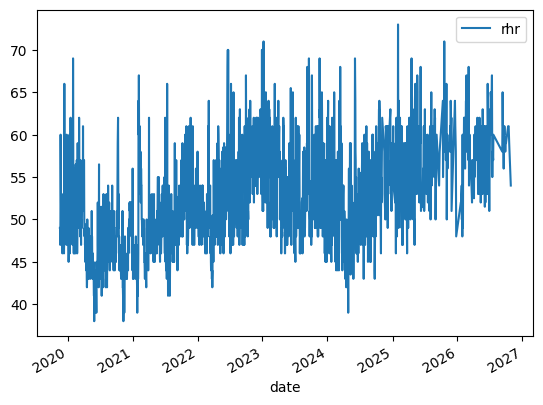

In [ ]:
import xml.etree.ElementTree as ET # load Python's built-in XML reader
import pandas as pd # library to handle table

rows = []
for _, el in ET.iterparse("apple_health_export/export.xml"):
    if el.tag == "Record" and el.get("type") == "HKQuantityTypeIdentifierRestingHeartRate": # keep only Record tag whose type is resting heart rate
        rows.append({"date": el.get("startDate")[:10], "rhr": float(el.get("value"))})
    el.clear()  # free memory

rhr = pd.DataFrame(rows) # turns into a table with columns date and rhr
rhr["date"] = pd.to_datetime(rhr["date"]) # converts the date into real dates
rhr = rhr.groupby("date").mean() # if a day has more than one value, average them into one
rhr.plot()

<Axes: xlabel='date'>

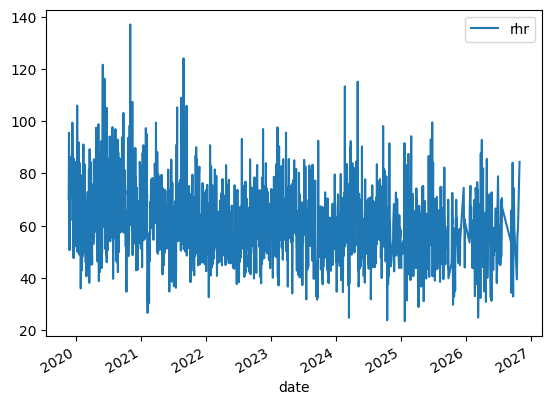

In [ ]:
import xml.etree.ElementTree as ET # load Python's built-in XML reader
import pandas as pd # library to handle table

rows = [] # list
for _, el in ET.iterparse("apple_health_export/export.xml"):
    if el.tag == "Record" and el.get("type") == "HKQuantityTypeIdentifierHeartRateVariabilitySDNN": # keep only Record tag whose type is resting heart rate
        rows.append({"date": el.get("startDate")[:10], "rhr": float(el.get("value"))})
    el.clear()  # free memory

hrv = pd.DataFrame(rows) # turns into a table with columns date and hrv
hrv["date"] = pd.to_datetime(hrv["date"]) # converts the date into real dates
hrv = hrv.groupby("date").mean() # if a day has more than one value, average them into one
hrv.plot()